# Analysis of Example 4: comparison with the data of the Perspective

Example 4 uses the two-mode model of the Perspective on detection-dependent dephasing in 2DES (Paiva-Ortega et al., 2026). The repository of the Perspective stores, for each scenario it simulated, ten samples of the rephasing spectrum along a cut through each diagonal peak, for every Liouville diagram and for their sum, together with the half width of the Lorentzian fitted to them. This notebook compares QuDPy-FDGF with these stored data. Nothing is recomputed with QuDPy: the script `compare_perspective.py` evaluates QuDPy-FDGF at the same ten points of each cut and applies the same estimator, and this notebook reads its results. In this notebook you will:

- see how the Perspective's numbers are produced (time grid, frequency labels, estimator) and why they differ from a fine-grid linewidth;
- compare the coherent signal and each diagram with the stored data for six scenarios;
- compare the action signal, and find the sign convention that reproduces the stored sum;
- check the exact identity between the excitation-number action signal and the polarization;
- see which detector the unbalanced scenario corresponds to, and what the PL projector of the paper gives.

Natural units: $\hbar=1$, energies and rates in eV (widths in meV), times in eV$^{-1}$.

## 0. Imports

`models.py` (in the parent folder) holds the model of Example 4. The comparison itself is computed by `compare_perspective.py`, which needs the folder `Data/Borealis Data` of the Perspective repository:

`python compare_perspective.py "<Perspective repo>/Data/Borealis Data"`

and writes `results/data/perspective_comparison.json`, which this notebook reads. Figures are saved in `results/figure_analysis/`.

In [1]:
import json
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np

from compare_perspective import AMPLITUDE_SCALE, DT_TRUE, LABEL_STEP, LABEL_TO_TRUE, N_POINTS, lorentzian_halfwidth
from models import ANALYSIS_FIGURES, DATA, EX4, EX4_PATHWAYS, EX4_PROTOCOL, example4_model, results_dirs
from qudpy_fdgf import ObservableSpec, SpectroscopySolver

results_dirs()
path = DATA / "perspective_comparison.json"
if not path.exists():
    raise SystemExit("Run compare_perspective.py with the Perspective data first (see the previous cell).")
comparison = json.loads(path.read_text())
scenarios = comparison["scenarios"]

## 1. How the Perspective's numbers are produced

The scripts of the Perspective (`Data/Borealis Data/Codes/`) give the following chain.

- **Time domain.** $t_1$ and $t_3$ run over $N=382$ points on $[0,801]$ eV$^{-1}$, without apodization, and `ifft2` gives the spectrum. The frequency labels use the step $1/\mathrm{Reso}=2.094$ eV$^{-1}$ instead of the true step $801/381=2.102$ eV$^{-1}$, so a label $w$ stands for the physical frequency $0.9962\,w$ and the label step is 7.85 meV.
- **Cut.** The ten samples are $|S|$ at $(\omega_1,\omega_3)=(-w,+w)$ with $w$ on the label grid in $[0.96,1.04]$ eV (peak $a$) or $[1.16,1.24]$ eV (peak $b$), for each diagram and for the sum.
- **Estimator.** A Lorentzian $A\gamma^2/[(x-x_0)^2+\gamma^2]$, with three free parameters and no offset, is fitted to the ten samples; $\gamma$ is the half width reported in Table I.
- **Coherent signal.** $R_1+R_2-R_3$ (stimulated emission, ground-state bleach, excited-state absorption subtracted), without radiative channels.
- **Action signal.** The four UFSS fluorescence diagrams $Q_{3a}$ (SE, $B_u$), $Q_{4a}$ (GSB, $B_u$), $Q_{2b}$ (ESA, $B_u$) and $Q_{8b}$ (ESA, $K_d$), with the detector $N_{\rm exc}=n_a+n_b$ read after a delay of 5 eV$^{-1}$, with the radiative channels, added with `np.sum`.

The raw QuDPy diagrams carry no factor $i$ per interaction, whereas the Liouville-space signals of QuDPy-FDGF carry $-i$ per ket-side and $+i$ per bra-side interaction. A diagram with $n_B$ bra-side and $n_K$ ket-side interactions therefore satisfies $S_{\rm FDGF}=(+i)^{n_B}(-i)^{n_K}S_{\rm raw}$, which gives the signs $(-1,-1,+1,-1)$ for $(Q_{3a},Q_{4a},Q_{2b},Q_{8b})$, and $(+i,+i,-i)$ for the third-order diagrams $(R_1,R_2,R_3)$. The continuous transform is $N^2\Delta t^2$ times the `ifft2` value, with $N\Delta t=803$ eV$^{-1}$.

In [2]:
print(f"N = {N_POINTS}, true step {DT_TRUE:.4f}, label step {1e3 * LABEL_STEP:.3f} meV, label -> physical frequency x {LABEL_TO_TRUE:.5f}")
print(f"(N dt)^2 = {AMPLITUDE_SCALE:.4g} eV^-2")

N = 382, true step 2.1024, label step 7.853 meV, label -> physical frequency x 0.99621
(N dt)^2 = 6.45e+05 eV^-2


## 2. Coherent signal

For each of the six scenarios of the repository (the reference, and the transfer rate changed from 5 meV to 10, 20, 1 and 0.1 meV, and the relaxation rate raised to 20 meV), we evaluate the three third-order pathways at the same ten points and apply the same estimator. The columns show the half width of the sum $R_1+R_2-R_3$ and, in the last two, the largest difference over the four rows (three diagrams and the sum).

In [3]:
print(f"{'scenario':<32}{'peak':>5}{'stored':>9}{'FDGF':>9}{'diff':>8}{'max diff over 4 rows (meV)':>28}")
rows_x3 = []
for name, report in scenarios.items():
    for peak, entry in report["peaks"].items():
        stored, fdgf = np.array(entry["X3_stored_meV"]), np.array(entry["X3_fdgf_meV"])
        rows_x3.append((stored, fdgf))
        print(f"{name:<32}{peak:>5}{stored[-1]:>9.3f}{fdgf[-1]:>9.3f}{fdgf[-1] - stored[-1]:>+8.3f}{np.abs(fdgf - stored).max():>28.3f}")

relative = np.concatenate([np.abs(f / s - 1) for s, f in rows_x3])
print(f"relative difference of the half widths (48 values): mean {relative.mean():.2%}, max {relative.max():.2%}")
assert relative.max() < 0.02

scenario                         peak   stored     FDGF    diff  max diff over 4 rows (meV)
Reference                           a    5.158    5.163  +0.005                       0.045
Reference                           b    7.096    7.102  +0.006                       0.064
Enhance Transfer trans = 0.01       a    5.182    5.185  +0.004                       0.045
Enhance Transfer trans = 0.01       b    8.911    8.903  -0.008                       0.078
Trans =0.02                         a    5.209    5.209  +0.001                       0.043
Trans =0.02                         b   12.662   12.661  -0.001                       0.218
Trans =  1E-3                       a    5.129    5.134  +0.006                       0.046
Trans =  1E-3                       b    5.589    5.605  +0.016                       0.059
Trans=1E-4                          a    5.120    5.125  +0.005                       0.046
Trans=1E-4                          b    5.234    5.254  +0.021                 

The half widths agree to 0.35 % on average and 1.4 % at most. The transfer rate, which widens the peak at $\omega_b$ from 5.2 to 12.7 meV, and the relaxation rate, which widens both peaks to 14 and 16 meV, are followed by the stored data to the same precision. No parameter of the model needs tuning: the rates, the coupling and the anharmonicity of the script are those of Example 4.

The amplitudes also agree. The stored values are on the scale of `ifft2`; the continuous transform is $N^2\Delta t^2$ times larger.

In [4]:
amplitude = np.array([a for report in scenarios.values() for entry in report["peaks"].values()
                      for a in entry["amplitude_ratio_X3"] + [entry["amplitude_ratio_X4_unsigned"]]])
print(f"|S_FDGF| / (stored x N^2 dt^2): mean {amplitude.mean():.3f}, min {amplitude.min():.3f}, max {amplitude.max():.3f} (60 values)")
assert 0.9 < amplitude.min() and amplitude.max() < 1.05

|S_FDGF| / (stored x N^2 dt^2): mean 0.980, min 0.918, max 1.009 (60 values)


The mean ratio of 0.98 and the spread of a few percent are consistent with what the time grid does and the frequency domain does not: the window ends at 801 eV$^{-1}$, where the narrowest coherence has decayed by $e^{-4.5}$ only, the step is 2.1 eV$^{-1}$, and the frequency labels are shifted by 0.4 %.

## 3. Action signal

The four diagrams with the delayed excitation-number detector are computed from the three pathways with the readout alternatives: $Q_{3a}$ is `R_SE` with $B_u$, $Q_{4a}$ is `R_GSB` with $B_u$, $Q_{2b}$ is `R_ESA` with $B_u$ and $Q_{8b}$ is `R_ESA` with $K_d$. Two sums are formed from the Liouville-space signals of QuDPy-FDGF.

- *Perspective signs*: the plain sum of the raw diagrams, $\sum_k S_{\rm FDGF}^{(k)}/\sigma_k$ with $\sigma=(-1,-1,+1,-1)$, which is `np.sum` of the raw QuDPy spectra.
- *Liouville signs*: $\sum_k S_{\rm FDGF}^{(k)}$, the same rule that gives $R_1+R_2-R_3$ for the coherent signal.

In [5]:
print(f"{'scenario':<32}{'peak':>5}{'stored':>9}{'Perspective signs':>19}{'Liouville signs':>17}{'coherent (stored)':>19}")
rows_x4 = []
for name, report in scenarios.items():
    for peak, entry in report["peaks"].items():
        stored, signs = entry["X4_stored_meV"][-1], entry["X4_fdgf_unsigned_meV"][-1]
        rows_x4.append((np.array(entry["X4_stored_meV"]), np.array(entry["X4_fdgf_unsigned_meV"])))
        print(f"{name:<32}{peak:>5}{stored:>9.3f}{signs:>19.3f}{entry['X4_fdgf_physical_meV']:>17.3f}{entry['X3_stored_meV'][-1]:>19.3f}")

relative = np.concatenate([np.abs(f / s - 1) for s, f in rows_x4])
print(f"relative difference, Perspective signs, 5 rows x 12 cuts: mean {relative.mean():.2%}, max {relative.max():.2%}")
assert relative.max() < 0.02

scenario                         peak   stored  Perspective signs  Liouville signs  coherent (stored)
Reference                           a    8.630              8.647            5.201              5.158
Reference                           b   10.995             11.047            7.141              7.096
Enhance Transfer trans = 0.01       a    8.600              8.622            5.224              5.182
Enhance Transfer trans = 0.01       b   12.680             12.775            8.939              8.911
Trans =0.02                         a    8.573              8.600            5.248              5.209
Trans =0.02                         b   16.040             16.256           12.691             12.662
Trans =  1E-3                       a    8.671              8.682            5.173              5.129
Trans =  1E-3                       b    9.767              9.788            5.647              5.589
Trans=1E-4                          a    8.684              8.692            5.164

With the plain sum of the raw diagrams, QuDPy-FDGF reproduces the stored action half widths and those of each diagram to 0.4 % on average and 1.4 % at most. With the Liouville signs, the action signal has the half width of the coherent signal in every scenario, to within 0.07 meV (the Liouville-signed sum includes the radiative channels, the coherent signal of the script does not).

The difference between the two sums is the sign of one diagram. In the Liouville-space formalism the four diagrams enter the sum with the same sign, $S_{Q3a}+S_{Q4a}+S_{Q2b}+S_{Q8b}$, which in the raw convention of QuDPy means $-S^{\rm raw}_{Q3a}-S^{\rm raw}_{Q4a}+S^{\rm raw}_{Q2b}-S^{\rm raw}_{Q8b}$, with the excited-state-absorption diagram $Q_{2b}$ of the opposite sign, as $R_3$ is subtracted in the coherent sum. The stored action data correspond to the sum in which $Q_{2b}$ is added with the other sign, as the following scan over all sign combinations shows.

In [6]:
import itertools

from compare_perspective import action_rows, lorentzian_halfwidth

labels = np.array(scenarios["Reference"]["peaks"]["a"]["labels_eV"])
labels_b = np.array(scenarios["Reference"]["peaks"]["b"]["labels_eV"])
diagram_a, diagram_b = action_rows({}, labels), action_rows({}, labels_b)
print("weights on the Liouville-space signals of (Q3a, Q4a, Q2b, Q8b)   half width a   half width b   (stored: "
      f"{scenarios['Reference']['peaks']['a']['X4_stored_meV'][-1]:.3f}, {scenarios['Reference']['peaks']['b']['X4_stored_meV'][-1]:.3f})")
for signs in itertools.product((1, -1), repeat=4):
    if signs[0] != 1:
        continue
    widths = [lorentzian_halfwidth(lab, np.abs(sum(s * row for s, row in zip(signs, rows))))
              for lab, rows in ((labels, diagram_a), (labels_b, diagram_b))]
    mark = "   <- stored data" if abs(widths[0] - 8.63) < 0.1 else ("   <- Liouville signs" if signs == (1, 1, 1, 1) else "")
    print(f"{str(signs):<65}{widths[0]:>12.3f}{widths[1]:>15.3f}{mark}")

weights on the Liouville-space signals of (Q3a, Q4a, Q2b, Q8b)   half width a   half width b   (stored: 8.630, 10.995)
(1, 1, 1, 1)                                                            5.201          7.141   <- Liouville signs
(1, 1, 1, -1)                                                           5.207          8.616
(1, 1, -1, 1)                                                           8.647         11.047   <- stored data
(1, 1, -1, -1)                                                          7.661         10.083
(1, -1, 1, 1)                                                           7.963         10.305
(1, -1, 1, -1)                                                          8.035         10.587
(1, -1, -1, 1)                                                          7.749         10.642
(1, -1, -1, -1)                                                         7.178         10.445


Only the combination $(+,+,-,+)$ gives the stored widths, 8.63 and 11.0 meV; the physical combination $(+,+,+,+)$ gives 5.20 and 7.14 meV, the widths of the coherent signal.

That the physical combination must give the coherent width is the exact identity of Example 4. With the readout alternatives summed, the action signal with the detector $N=n_a+n_b$, read right after the fourth interaction, equals $-i$ times the polarization pathway by pathway, and a delay of 5 eV$^{-1}$ before the readout, as in the script, changes this by less than 1 %. We check the identity on the ten points of the cut, with and without the delay.

In [7]:
from compare_perspective import detector_model, evaluate


def identity_error(delay):
    model = detector_model({}, delay=delay)
    observables = {"polarization": "polarization",
                   "action": ObservableSpec.action("action", fourth_interaction=("Bu", "Kd"), operator="N_delayed")}
    result = evaluate(model, labels, observables)
    total = lambda name: sum(np.diag(result.observables[name][p.name]) for p in EX4_PATHWAYS)
    return np.max(np.abs(total("action") + 1j * total("polarization"))) / np.max(np.abs(total("polarization")))


for delay in (0.0, 5.0):
    print(f"delay {delay:>3} eV^-1: max|S_N + i S_pol| / max|S_pol| = {identity_error(delay):.1e}")
assert identity_error(0.0) < 1e-12
assert identity_error(5.0) < 0.02

delay 0.0 eV^-1: max|S_N + i S_pol| / max|S_pol| = 1.3e-16
delay 5.0 eV^-1: max|S_N + i S_pol| / max|S_pol| = 5.4e-03


## 4. The unbalanced scenario

The Perspective describes the third column of its Fig. 2 as unbalanced action-detection weights $\eta_1=2\eta_2$, but its repository has no script for it: the stored data differ from the reference only in the action signal, 8.44 and 10.75 meV against 8.63 and 11.0 meV. We look for the detector among the family $N=n_a+n_b-(1-\nu)(a^\dagger a^\dagger aa+b^\dagger b^\dagger bb)$, where $\nu=1$ is the excitation number and $\nu<1$ lowers the weight of the two-quantum states. The scan below uses the Perspective's signs, since they reproduce the stored data.

stored: [ 8.442 10.745]  nu reproducing each width: [0.47 0.43]


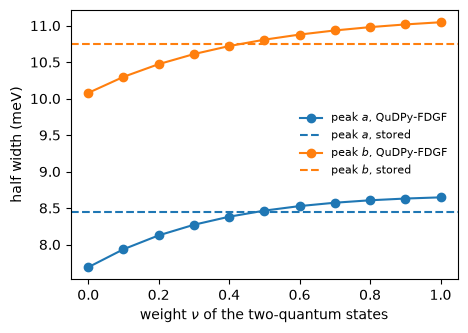

In [8]:
scan = comparison["unbalanced"]["scan"]
stored = comparison["unbalanced"]["stored_X4_meV"]
nus = np.array([float(k) for k in scan])
values = np.array(list(scan.values()))
fig, ax = plt.subplots(figsize=(5, 3.5))
for column, label, color in ((0, r"peak $a$", "tab:blue"), (1, r"peak $b$", "tab:orange")):
    ax.plot(nus, values[:, column], "-o", color=color, label=f"{label}, QuDPy-FDGF")
    ax.axhline(stored[column], color=color, linestyle="--", label=f"{label}, stored")
ax.set_xlabel(r"weight $\nu$ of the two-quantum states")
ax.set_ylabel("half width (meV)")
ax.legend(frameon=False, fontsize=8)
unbalanced_figure = fig
nu_best = [float(np.interp(s, values[:, c], nus)) for c, s in enumerate(stored)]
print("stored:", np.round(stored, 3), " nu reproducing each width:", np.round(nu_best, 2))

The stored widths are reached for $\nu\approx0.45$ at both peaks (0.47 and 0.43), where $\nu=0.5$ gives 8.47 and 10.81 meV, 0.3 and 0.6 % higher. A fit of free weights on the nine eigenstates to the stored diagram data (not included here) also finds weights of 1 on the one-quantum states, equal for $a$ and $b$, and about 1 on $|2_a\rangle$ and $|2_b\rangle$. The unbalanced scenario therefore seems to lower the detection weight of the two-quantum states, not to weight the two one-quantum states 2:1; the repository does not say how, and this identification stays approximate.

## 5. The photoluminescence projector of the paper

The paper defines the action detector as the projector $A_{\rm PL}=\eta_1|e_1\rangle\langle e_1|+\eta_2|e_2\rangle\langle e_2|$ on the one-quantum eigenstates, not the excitation number of the script. Its action signal, complete with the Liouville signs, evaluated at the same ten points with the same estimator, gives the following half widths.

In [9]:
print(f"{'scenario':<32}{'peak':>5}{'coherent':>10}{'A_PL equal':>12}{'A_PL 2:1':>10}{'N_exc':>8}{'stored action':>15}")
for name, entry in comparison["projector"].items():
    for peak, values in entry.items():
        coherent = scenarios[name]["peaks"][peak]["X3_stored_meV"][-1]
        print(f"{name:<32}{peak:>5}{coherent:>10.3f}{values['A_PL']:>12.3f}{values['A_PL_unbalanced']:>10.3f}"
              f"{values['N_exc']:>8.3f}{values['stored_X4_meV']:>15.3f}")

scenario                         peak  coherent  A_PL equal  A_PL 2:1   N_exc  stored action
Reference                           a     5.158       8.071     8.051   5.204          8.630
Reference                           b     7.096      10.554    10.615   7.137         10.995
Enhance Transfer trans = 0.01       a     5.182       8.053     8.041   5.226          8.600
Enhance Transfer trans = 0.01       b     8.911      12.708    12.640   8.936         12.680


The PL projector gives half widths of 8.07 and 10.55 meV, against 5.16 and 7.10 meV for the coherent signal: the action signal is broader than the coherent one by about 3 meV at both peaks, because the projector does not see the two-quantum population left by the excited-state absorption, whereas the excitation number does and reproduces the coherent signal exactly. With transfer raised to 10 meV, the peak at $\omega_b$ reaches 12.71 meV, against 12.68 meV in the stored data. The projector therefore carries the effect that the Perspective describes, within 0.6 meV of its Table I, even though the stored action data come from the excitation number with the signs of Section 3.

## 6. Diagram by diagram

The stored data hold one row of ten samples per Liouville diagram. Compared one by one, the diagrams do not depend on the convention used to combine them. For the eight rows (the three coherent diagrams $R_1$, $R_2$, $R_3$ and their sum; the four action diagrams $Q_{3a}$, $Q_{4a}$, $Q_{2b}$, $Q_{8b}$) we compare, for the reference scenario, the half width stored and from QuDPy-FDGF, the mean amplitude ratio in units of $(N\Delta t)^2$ (1 is a perfect agreement of the scale of the transform), and the shape deviation: the largest difference between the ten samples once this scale is removed, in percent of the largest sample. The action sum is left out.

In [10]:
names = ("R1", "R2", "R3", "coherent_sum", "Q3a", "Q4a", "Q2b", "Q8b")
reference = scenarios["Reference"]["peaks"]
print(f"{'':<14}" + "".join(f"{'peak ' + peak:>38}" for peak in ("a", "b")))
print(f"{'diagram':<14}" + "".join(f"{'stored':>10}{'FDGF':>9}{'ampl.':>9}{'shape %':>10}" for _ in ("a", "b")))
width_deviation, amplitudes, shapes = [], [], []
for name in names:
    line = f"{name:<14}"
    for peak in ("a", "b"):
        entry = reference[peak]
        index = names.index(name)
        stored = (entry["X3_stored_meV"] + entry["X4_stored_meV"][:4])[index]
        fdgf = (entry["X3_fdgf_meV"] + entry["X4_fdgf_unsigned_meV"][:4])[index]
        amplitude, shape = entry["diagram_amplitude_shape"][name]
        line += f"{stored:>10.3f}{fdgf:>9.3f}{amplitude:>9.3f}{100 * shape:>10.1f}"
    print(line)

for report in scenarios.values():                     # all scenarios, all eight rows, both peaks
    for entry in report["peaks"].values():
        stored = entry["X3_stored_meV"] + entry["X4_stored_meV"][:4]
        fdgf = entry["X3_fdgf_meV"] + entry["X4_fdgf_unsigned_meV"][:4]
        width_deviation += [abs(f / s - 1) for s, f in zip(stored, fdgf)]
        amplitudes += [a for a, _ in entry["diagram_amplitude_shape"].values()]
        shapes += [s for _, s in entry["diagram_amplitude_shape"].values()]
print(f"six scenarios, eight rows, two peaks ({len(shapes)} values): half width within {max(width_deviation):.1%} "
      f"(mean {np.mean(width_deviation):.2%}), amplitude ratio {min(amplitudes):.3f} to {max(amplitudes):.3f}, "
      f"shape deviation at most {max(shapes):.1%}")
assert max(width_deviation) < 0.02 and 0.9 < min(amplitudes) and max(amplitudes) < 1.05 and max(shapes) < 0.04

                                              peak a                                peak b
diagram           stored     FDGF    ampl.   shape %    stored     FDGF    ampl.   shape %
R1                 5.559    5.604    0.999       0.6     8.107    8.171    1.002       2.5
R2                 5.321    5.320    0.982       0.2     7.880    7.878    0.954       1.0
R3                 7.533    7.511    0.988       0.6    10.326   10.352    0.990       1.7
coherent_sum       5.158    5.163    1.009       0.2     7.096    7.102    0.983       0.4
Q3a                5.609    5.655    0.999       0.6     8.158    8.222    1.002       2.5
Q4a                5.372    5.371    0.982       0.2     7.930    7.928    0.954       1.0
Q2b                7.833    7.805    0.987       0.7    10.532   10.558    0.989       1.7
Q8b                8.105    8.070    0.985       0.8    10.711   10.735    0.989       1.6
six scenarios, eight rows, two peaks (96 values): half width within 1.4% (mean 0.39%), amp

Each diagram agrees with its stored counterpart to 0.8 % in half width in the reference scenario and to 1.4 % over the six scenarios, with an amplitude within 5 % (8 % over the six scenarios) and a shape within 3.2 % of the peak maximum. The diagrams are the individual contributions that the Perspective's time-domain run computed, so what remains is the difference between that run and the frequency-domain evaluation: a finite window of 801 eV$^{-1}$ (the slowest coherence has decayed by $e^{-4.4}$ at its end), a time step of 2.1 eV$^{-1}$, and the shift of the frequency labels. The $R_1$ and $Q_{3a}$ rows, and likewise $R_2$ and $Q_{4a}$, differ only by the radiative channels, which the action runs include and the coherent runs do not.

## 7. The estimator

The Perspective's half widths come from ten samples 7.85 meV apart, fitted with a Lorentzian without offset. The signal is the sum of three pathways, one of them displaced by the anharmonicity and of opposite sign, and is not a Lorentzian; a fit on a fine grid with an offset gives other values. We compare the two on the coherent signal of the reference scenario, along the same line $(-w,+w)$.

 peak   ten-point estimator (their cut)        same estimator, fine cut


    a                             5.163                           5.625
    b                             7.102                           7.254


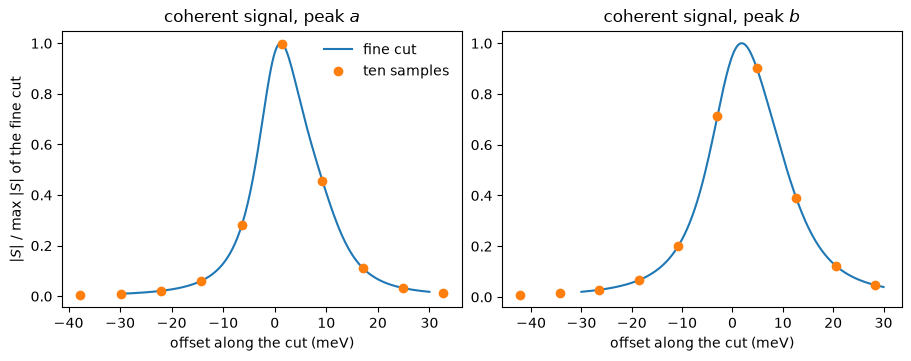

In [11]:
solver = SpectroscopySolver(backend="dense", eta=EX4["eta"])
solver.feed_model(example4_model(k_rad=0.0))                        # the Perspective's coherent signal has no radiative channel
offsets = np.linspace(-0.030, 0.030, 241)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
print(f"{'peak':>5}{'ten-point estimator (their cut)':>34}{'same estimator, fine cut':>32}")
for axis, (peak, key) in zip(axes, ((EX4["omega_a"], "a"), (EX4["omega_b"], "b"))):
    fine = solver.generate_spectrum(EX4_PROTOCOL, {"omega_1q": -peak - offsets, "omega_emit": peak + offsets},
                                    pathways=EX4_PATHWAYS, fixed_coordinates={"t2": EX4["t2"]})
    cut = np.abs(sum(np.diag(fine.pathways[p.name]) for p in EX4_PATHWAYS))
    peak_labels = np.array(scenarios["Reference"]["peaks"][key]["labels_eV"])
    coarse = evaluate(example4_model(k_rad=0.0), peak_labels, {"polarization": "polarization"})
    samples = np.abs(sum(np.diag(coarse.observables["polarization"][p.name]) for p in EX4_PATHWAYS))

    fine_width = lorentzian_halfwidth(offsets, cut)               # the same estimator on 241 points
    print(f"{key:>5}{lorentzian_halfwidth(peak_labels, samples):>34.3f}{fine_width:>32.3f}")
    axis.plot(1e3 * offsets, cut / cut.max(), label="fine cut")
    axis.plot(1e3 * (peak_labels * LABEL_TO_TRUE - peak), samples / cut.max(), "o", label="ten samples")
    axis.set_title(rf"coherent signal, peak ${key}$")
    axis.set_xlabel("offset along the cut (meV)")
axes[0].set_ylabel("$|S|$ / max $|S|$ of the fine cut")
axes[0].legend(frameon=False)
estimator_figure = fig
unbalanced_figure.savefig(ANALYSIS_FIGURES / "example4_analysis_unbalanced.pdf", bbox_inches="tight")
estimator_figure.savefig(ANALYSIS_FIGURES / "example4_analysis_estimator.pdf", bbox_inches="tight")

The ten-point estimator gives 5.16 and 7.10 meV and the same fit on the 241 points of a fine cut gives 5.63 and 7.25 meV: the shape is not a Lorentzian, so the number depends on the sampling. The estimator is the same for the coherent and the action signal, and the stored comparison between them is consistent; but the absolute half widths of Table I are those of this estimator, and the direction of the cut does not matter (the fine cut along $(-w,+w)$ and along the perpendicular direction give the same widths to 0.02 meV).

## Summary

- QuDPy-FDGF reproduces the stored coherent data of the Perspective for six scenarios, with no parameter to tune: the half widths agree to 0.35 % on average and 1.4 % at most (48 values), and the amplitudes to a few percent.
- The stored action data are reproduced to the same precision by the four UFSS fluorescence diagrams with the excitation-number detector, summed with the signs of the raw QuDPy diagrams.
- With the signs of the Liouville-space formalism, the same four diagrams give the half widths of the coherent signal, as the exact identity $S_N=-iS_{\rm pol}$ requires. The stored action widths (8.63 and 11.0 meV) come from the sum in which the excited-state-absorption diagram $Q_{2b}$ has the opposite sign.
- The photoluminescence projector of the paper gives action half widths 3 meV above the coherent ones (8.07 and 10.55 meV), within 0.6 meV of Table I: the effect is real for this detector.
- The unbalanced scenario is compatible with a lower detection weight of the two-quantum states ($\nu\approx0.45$), not with weights 2:1 on the one-quantum states; the repository does not contain its script.
- The half widths of Table I are those of a ten-point estimator; the same fit on a fine cut gives 5.63 and 7.25 meV for the coherent signal.